In [27]:
!pip install -q kagglehub

In [28]:
import os
import pathlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [29]:
dataset_path = kagglehub.dataset_download(
    "feyzazkefe/trashnet"
)

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'trashnet' dataset.
Dataset downloaded to: /kaggle/input/trashnet


In [30]:
classes = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

data_dir = None

for root, dirs, files in os.walk(dataset_path):
    folder_names = {d.lower() for d in dirs}

    if set(classes).issubset(folder_names):
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "Could not find all six class folders. "
        "Check the downloaded dataset folder structure."
    )

print("Image folder:", data_dir)

Image folder: /kaggle/input/trashnet/dataset-resized


In [31]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

class_counts = {}

for class_name in classes:

    folder = os.path.join(data_dir, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ]

    class_counts[class_name] = len(images)

print(pd.Series(class_counts))

cardboard    403
glass        501
metal        410
paper        594
plastic      482
trash        137
dtype: int64


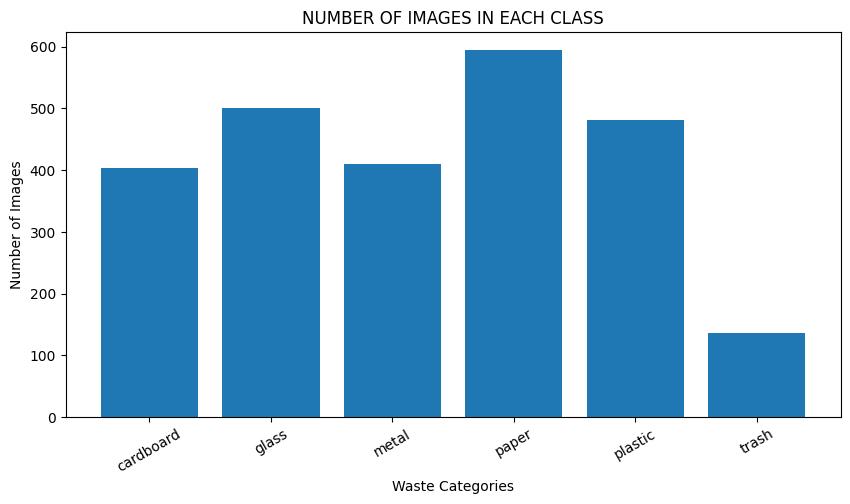

In [32]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("NUMBER OF IMAGES IN EACH CLASS")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.show()

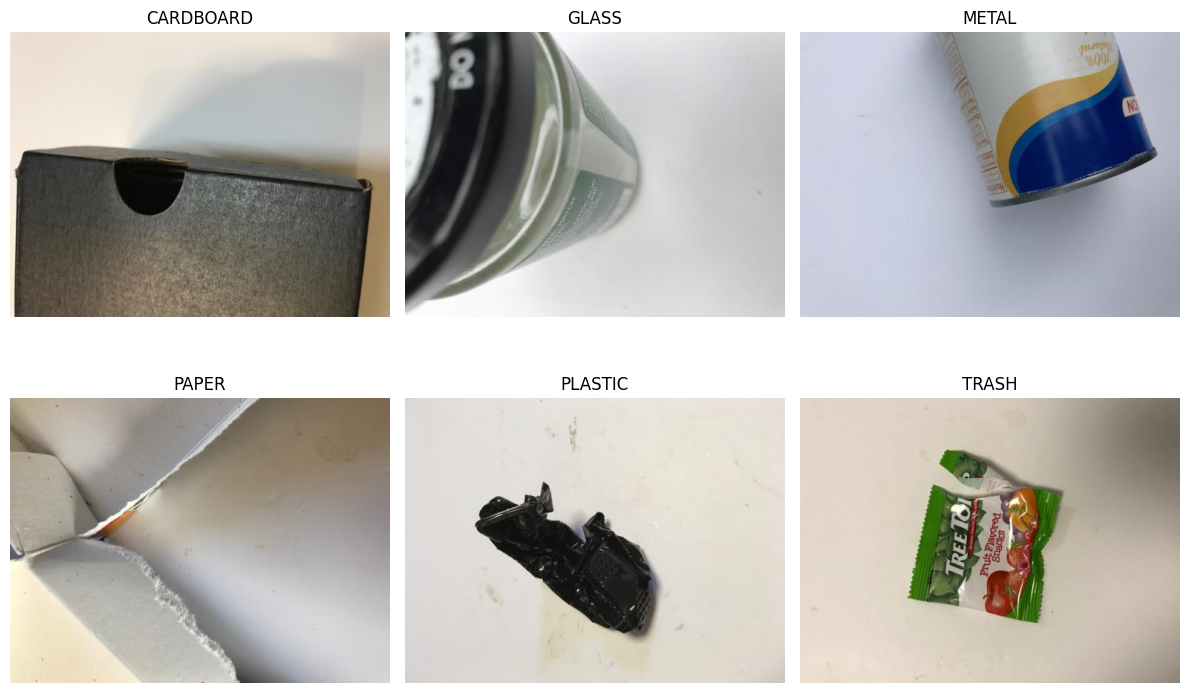

In [33]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):

    folder = os.path.join(data_dir, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ]

    image_path = os.path.join(folder, image_files[0])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.upper())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
image_paths = []
labels = []

for label, class_name in enumerate(classes):

    folder = os.path.join(data_dir, class_name)

    for file in os.listdir(folder):

        if file.lower().endswith(image_extensions):

            image_paths.append(
                os.path.join(folder, file)
            )

            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

Total images: 2527
Total labels: 2527


In [35]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 1768
Validation images: 379
Testing images: 380


In [36]:
IMG_SIZE = 128
BATCH_SIZE = 32

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [37]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

train_ds = (
    train_ds
    .shuffle(1000)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Dataset preprocessing completed!")

Dataset preprocessing completed!


In [38]:
from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),

    # First CNN block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Second CNN block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Third CNN block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Fourth CNN block
    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Classification layers
    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(6, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [39]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [40]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(i): float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("Class weights:", class_weights)

Class weights: {0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


In [41]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_waste_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.4304 - loss: 1.5893 - val_accuracy: 0.3008 - val_loss: 1.7275 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.5198 - loss: 1.3105 - val_accuracy: 0.1821 - val_loss: 2.1545 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.5396 - loss: 1.2312 - val_accuracy: 0.2797 - val_loss: 1.9154 - learning_rate: 0.0010
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.5967 - loss: 1.1268 - val_accuracy: 0.3272 - val_loss: 2.0995 - learning_rate: 0.0010
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.6176 - loss: 1.0063 - val_accuracy: 0.1900 - val_loss: 2.0483 - learning_rate: 5.0000e-04
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.6312 - loss: 1.0014 - val_accuracy: 0.2929 - val_loss: 2.1076 - learning_rate: 5.0000e-04
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.6601 - loss: 0.92

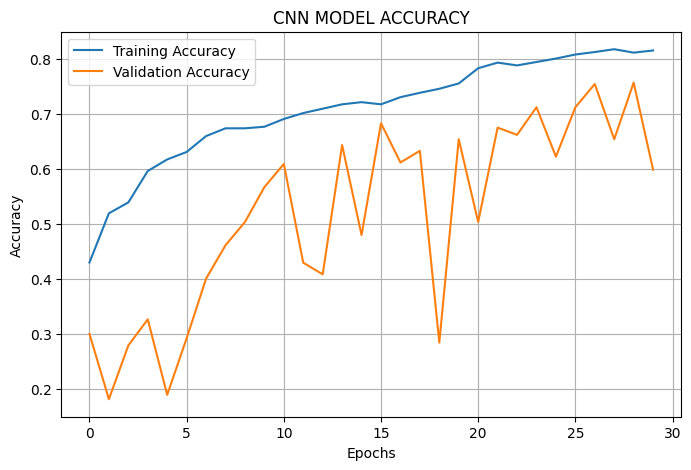

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN MODEL ACCURACY")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

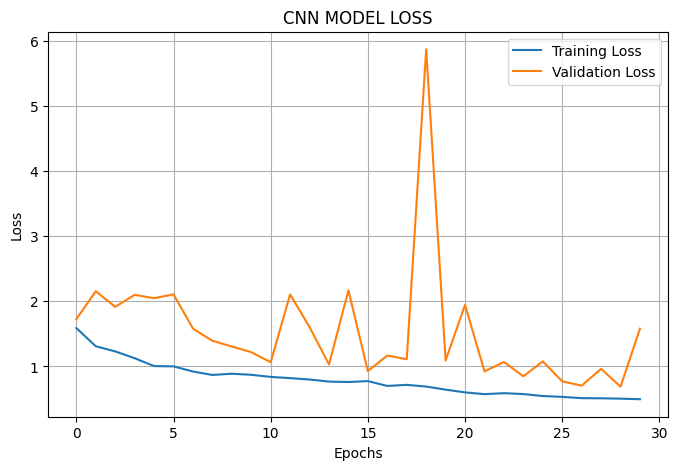

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN MODEL LOSS")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [44]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.6868 - loss: 0.8631
Test Loss: 0.8630837798118591
Test Accuracy: 68.68420839309692 %


In [45]:
print("Final Training Accuracy:",
      history.history["accuracy"][-1] * 100, "%")

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1] * 100, "%")

print("Final Training Loss:",
      history.history["loss"][-1])

print("Final Validation Loss:",
      history.history["val_loss"][-1])

Final Training Accuracy: 81.56108856201172 %
Final Validation Accuracy: 59.89446043968201 %
Final Training Loss: 0.49713239073753357
Final Validation Loss: 1.5802154541015625


In [46]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

IMG_SIZE = 224

def load_image_transfer(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = preprocess_input(image)

    return image, label

In [47]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    train_ds.shuffle(1000)
    .map(load_image_transfer,
         num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds.map(load_image_transfer,
               num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds.map(load_image_transfer,
                num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

In [48]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    6,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [49]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            patience=2,
            factor=0.5
        )
    ]
)

Epoch 1/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 141ms/step - accuracy: 0.4762 - loss: 1.4209 - val_accuracy: 0.7045 - val_loss: 0.8549 - learning_rate: 0.0010
Epoch 2/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.6895 - loss: 0.8240 - val_accuracy: 0.7652 - val_loss: 0.6843 - learning_rate: 0.0010
Epoch 3/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.7523 - loss: 0.6731 - val_accuracy: 0.7731 - val_loss: 0.6189 - learning_rate: 0.0010
Epoch 4/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.7805 - loss: 0.6139 - val_accuracy: 0.7968 - val_loss: 0.6169 - learning_rate: 0.0010
Epoch 5/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.8054 - loss: 0.5385 - val_accuracy: 0.8127 - val_loss: 0.5520 - learning_rate: 0.0010
Epoch 6/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.8133 - loss: 0.5079 - val_accuracy: 0.8074 - val_loss: 0.5586 - learning_rate: 0.0010
Epoch 7/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.8247 - loss: 0.4799 - val_a

In [50]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("New Test Accuracy:",
      test_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step - accuracy: 0.8711 - loss: 0.4539
New Test Accuracy: 87.1052622795105 %


In [51]:
y_true = []
y_pred = []

for images, labels_batch in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels_batch.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions completed!")

Predictions completed!


In [52]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

   cardboard       1.00      0.92      0.96        60
       glass       0.91      0.92      0.92        76
       metal       0.90      0.84      0.87        62
       paper       0.90      0.91      0.91        89
     plastic       0.83      0.79      0.81        73
       trash       0.50      0.75      0.60        20

    accuracy                           0.87       380
   macro avg       0.84      0.86      0.84       380
weighted avg       0.88      0.87      0.87       380



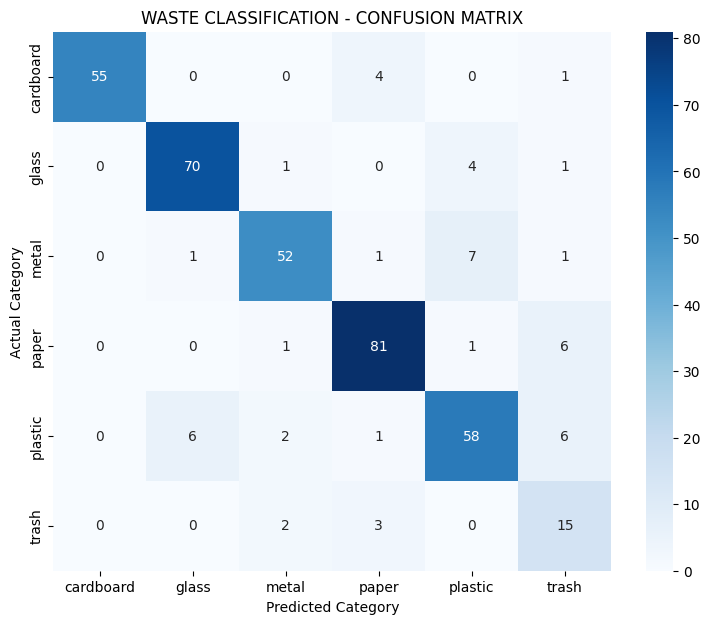

In [53]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("WASTE CLASSIFICATION - CONFUSION MATRIX")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

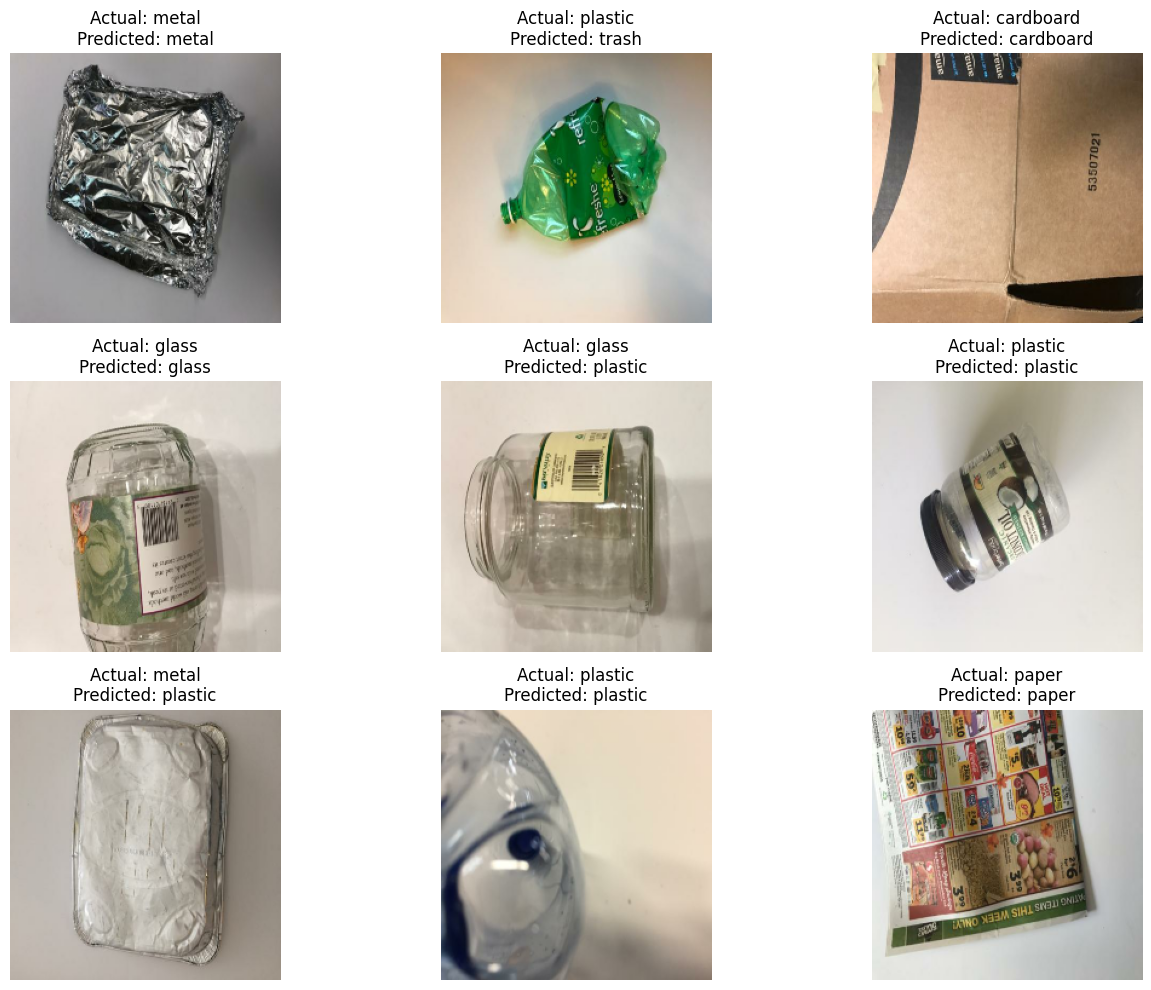

In [54]:
plt.figure(figsize=(14, 10))

for i in range(9):

    image, label = load_image(
        X_test[i],
        y_test[i]
    )

    prediction = model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_label = np.argmax(prediction)

    plt.subplot(3, 3, i + 1)

    plt.imshow(image.numpy())

    plt.title(
        f"Actual: {classes[label]}\n"
        f"Predicted: {classes[predicted_label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
model.save("/content/waste_classification_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [56]:
from google.colab import files

files.download(
    "/content/waste_classification_cnn.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
from google.colab import files

uploaded = files.upload()

Saving metal-tin-cans-foods-fruits-vegetables-legumes-tuna-meat-easy-open-white-background-high-low-angle_461160-9028.avif to metal-tin-cans-foods-fruits-vegetables-legumes-tuna-meat-easy-open-white-background-high-low-angle_461160-9028.avif


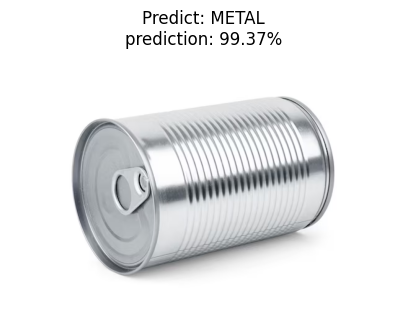

Predicted Category: METAL
prediction: 99.37 %


In [63]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

classes = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

for filename in uploaded.keys():

    # Load image
    img = Image.open(filename).convert("RGB")

    # Resize image
    img_resized = img.resize((224, 224))

    # Convert image to array
    img_array = np.array(img_resized)

    # Preprocess image
    img_array = preprocess_input(img_array.astype(np.float32))

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array, verbose=0)

    predicted_class = np.argmax(prediction[0])

    confidence = prediction[0][predicted_class] * 100

    # Display image
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Predict: {classes[predicted_class].upper()}\n"
        f"prediction: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Category:", classes[predicted_class].upper())
    print("prediction:", round(confidence, 2), "%")